### Deep Agents overview



Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.


### When to use deep agents
Use deep agents when you need agents that can:

- Handle complex, multi-step tasks that require planning and decomposition
- Manage large amounts of context through file system tools
- Delegate work to specialized subagents for context isolation
- Persist memory across conversations and threads

In [2]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()
os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [5]:
### Tools- Internet search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)


In [26]:
from langchain.chat_models import init_chat_model

model=init_chat_model("groq:openai/gpt-oss-20b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000025D55062710>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000025D55063110>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

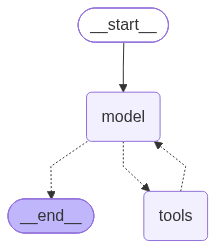

In [27]:
from langchain.agents import create_agent
simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

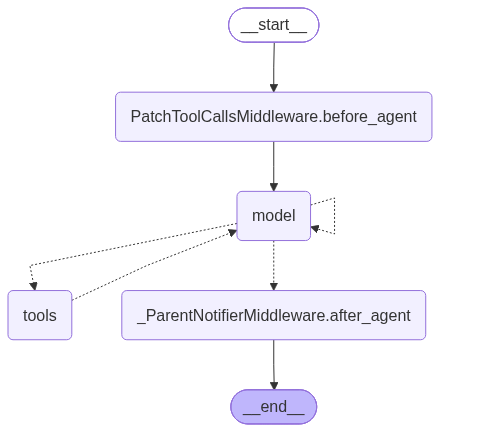

In [28]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[],#web_search  token limit issues
    system_prompt="Act as a researcher"
)
deepagent

In [29]:
# result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result = deepagent.invoke({
    "messages": [
        {"role": "user", "content": "What is a deep agent?"}
    ]
})
result

{'messages': [HumanMessage(content='What is a deep agent?', additional_kwargs={}, response_metadata={}, id='3005b264-1a41-4948-8004-6af787af4d03'),
  AIMessage(content="A **deep agent** is an AI system that uses *deep learning* (neural networks with many layers) as the core of its decision‑making or control logic. The term is most often used in the context of **reinforcement learning (RL)**, but it can also appear in supervised or unsupervised settings where the agent’s policy or value function is represented by a deep neural network.\n\n---\n\n## 1. Core Idea\n\n| Feature | What it means |\n|---------|----------------|\n| **Deep neural network** | The agent’s internal model (policy, value, or Q‑function) is a network with several hidden layers, enabling it to learn complex, high‑dimensional representations. |\n| **Agent** | A system that interacts with an environment, receives observations, takes actions, and receives rewards or feedback. |\n| **Learning from experience** | The agent 

In [30]:
result["messages"][-1].content

"A **deep agent** is an AI system that uses *deep learning* (neural networks with many layers) as the core of its decision‑making or control logic. The term is most often used in the context of **reinforcement learning (RL)**, but it can also appear in supervised or unsupervised settings where the agent’s policy or value function is represented by a deep neural network.\n\n---\n\n## 1. Core Idea\n\n| Feature | What it means |\n|---------|----------------|\n| **Deep neural network** | The agent’s internal model (policy, value, or Q‑function) is a network with several hidden layers, enabling it to learn complex, high‑dimensional representations. |\n| **Agent** | A system that interacts with an environment, receives observations, takes actions, and receives rewards or feedback. |\n| **Learning from experience** | The agent improves its behavior by updating the network weights based on past interactions (e.g., gradient descent on a loss derived from a reward signal). |\n\n---\n\n## 2. Typi

In [31]:
result['files']

{}

### What happened?

Your deep agent automatically:
- Planned its approach: Used the built-in write_todos tool to break down the research task
- Conducted research: Called the internet_search tool to gather information
- Managed context: Used file system tools (write_file, read_file) to offload large search results
- Spawned subagents (if needed): Delegated complex subtasks to specialized subagents
- Synthesized a report: Compiled findings into a coherent response

### Customizing Deep Agents

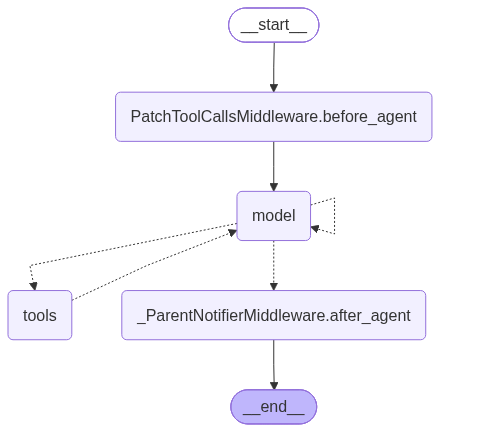

In [34]:
## #Model
from langchain.chat_models import init_chat_model
from deepagents import create_deep_agent

model = init_chat_model(model="groq:openai/gpt-oss-20b")#gpt-5
agent = create_deep_agent(model=model)
agent

In [35]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='8a93f05d-9a31-452a-97ac-0f9f0e5d6706'),
  AIMessage(content='**DeepAgent** is a term that generally refers to an AI system or framework designed to perform complex tasks by combining deep learning techniques with autonomous agent capabilities. In practice, a DeepAgent usually:\n\n1. **Performs perception** – uses deep neural networks (CNNs, transformers, etc.) to interpret raw sensory data (images, text, sensor streams).\n2. **Reasoning and planning** – applies reinforcement learning or symbolic reasoning to decide what actions to take in a given environment.\n3. **Actuation** – executes those actions, often in a simulated or real-world setting (robots, virtual assistants, game AI, etc.).\n4. **Learning** – continually updates its internal models based on feedback from the environment, improving performance over time.\n\nExamples of DeepAgent‑style systems include:\n- **OpenAI’s DAL

### System Prompt
Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents.
Each deep agent tailored to a use case should include a custom system prompt specific to that use case.

In [36]:
from deepagents import create_deep_agent

research_instructions = """\
You are an expert researcher. Your job is to conduct \
thorough research, and then write a polished report. \
"""

agent = create_deep_agent(
    model=model,
    system_prompt=research_instructions
)

result = agent.invoke(
    {"messages":[{"role": "user", "content": "What is deepagent?"}]}
)
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='26ce85cb-06ec-4521-ba63-e03477cead8b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to answer: "What is deepagent?" Likely referring to "DeepAgent" maybe a product, or "DeepAgent" in software? Could be a library? Might refer to "Deep Agent" in the context of AI or software. We need to provide a thorough answer. We can search. Let\'s search web? We have no internet. But maybe the user expects explanation of "deepagent" concept. Could be "DeepAgent" is a type of AI agent that uses deep learning. Or "DeepAgent" is a library for building AI agents. We might need to research. Let\'s search within the environment? There\'s no internet. But maybe we can search local files? Probably no. So we need to rely on knowledge. Let\'s think: "DeepAgent" might refer to "DeepAgent" open-source library from DeepMind? There\'s "DeepSpeed" from Microsoft. "DeepAgent" maybe a 

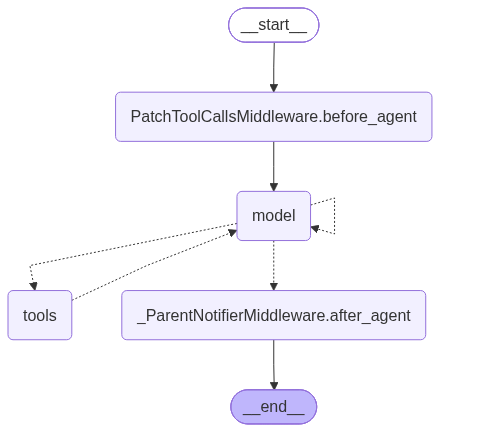

In [37]:
agent

In [38]:
### Tools
import os
from typing import Literal
from tavily import TavilyClient
from deepagents import create_deep_agent

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

agent = create_deep_agent(
    model=model,
    tools=[internet_search]
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent in Agentic AI?"}]})
result

{'messages': [HumanMessage(content='What is deepagent in Agentic AI?', additional_kwargs={}, response_metadata={}, id='a736165a-288a-41bf-8454-6e6b6e826728'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is deepagent in Agentic AI?" They likely refer to a concept in AI, maybe a deep agent within an agentic AI framework. Could be a term from some literature or product. Let\'s search.', 'tool_calls': [{'id': 'fc_2ec90d03-5450-4736-b179-9a81b3e3de9a', 'function': {'arguments': '{"include_raw_content":false,"max_results":5,"query":"deepagent in Agentic AI","topic":"general"}', 'name': 'internet_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 91, 'prompt_tokens': 1971, 'total_tokens': 2062, 'completion_time': 0.101067659, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0.128016077, 'prompt_tokens_details': None, 'queue_time': 0.344453947, 'total_time': 0.229083736}, 'model_name': 'openai/